In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
import pandas as pd
import numpy as np
from torch.utils.data import Dataset, DataLoader,TensorDataset
import ipaddress
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pickle

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


This function loads feature and label data from pickle files and converts them into PyTorch tensors for use in deep learning models. The feature data is reshaped to match the expected input format for a neural network, ensuring compatibility with PyTorch's data processing pipeline. The labels are also transformed into the appropriate tensor shape for training and evaluation

In [2]:
def load_pickle_data(feature_file, label_file):
    
    # Load feature data
    with open(feature_file, 'rb') as f:
        X = pickle.load(f)
    with open(label_file, 'rb') as f:
        y = pickle.load(f)



    # Ensure X has the correct shape (num_samples, num_features)
    if X.ndim == 2:  # If shape is (num_samples, num_features)
        X = X[: , np.newaxis, :]  # Convert to (num_samples, num_features, sequence_length=1)

    # Convert to PyTorch tensor
    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32).unsqueeze(1)  # Ensure shape (num_samples, 1)

    return X, y


This section defines a residual block, a key component of the ResNet-1D architecture. Each residual block consists of two 1D convolutional layers with batch normalization and ReLU activation. A skip connection (identity mapping) allows gradients to flow through the network more efficiently, helping to mitigate the vanishing gradient problem. If the input and output dimensions differ, a downsampling layer ensures proper alignment before the residual connection is applied

In [3]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock, self).__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.downsample = downsample

    def forward(self, x):
        identity = x
        if self.downsample is not None:
            identity = self.downsample(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out += identity
        out = self.relu(out)
        return out

This section defines the ResNet-1D architecture for anomaly detection in network traffic. The model consists of an initial convolutional layer followed by multiple residual blocks, which help preserve gradient flow and improve feature extraction. The network progressively increases feature depth while reducing temporal resolution using strided convolutions. A global average pooling layer reduces the spatial dimensions before passing the output through fully connected layers with dropout for regularization. The final layer applies a sigmoid activation function for binary classification.

In [4]:
class ResNet1D(nn.Module):
    def __init__(self, input_channels=1, num_classes=1):  # Update input_channels to 15
        super(ResNet1D, self).__init__()
        self.initial_layer = nn.Sequential(
            nn.Conv1d(in_channels=input_channels, out_channels=64, kernel_size=3, stride=1, padding=1, bias=False),  # Change in_channels=1
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True)
        )

        # Residual Blocks
        self.layer1 = self._make_layer(64, 128, blocks=2, stride=1)
        self.layer2 = self._make_layer(128, 256, blocks=2, stride=2)
        self.layer3 = self._make_layer(256, 512, blocks=2, stride=2)

        self.global_avg_pool = nn.AdaptiveAvgPool1d(1)

        # Fully connected layers
        self.fc = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def _make_layer(self, in_channels, out_channels, blocks, stride):
        downsample = None
        if stride != 1 or in_channels != out_channels:
            downsample = nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )

        layers = [ResidualBlock(in_channels, out_channels, stride, downsample)]
        for _ in range(1, blocks):
            layers.append(ResidualBlock(out_channels, out_channels))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.initial_layer(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.global_avg_pool(x)
        x = x.view(x.size(0), -1)
        x = self.fc(x)
        return x


This function trains the given model using a specified dataset and optimization strategy. The training loop iterates through mini-batches, computes the loss using a defined criterion, performs backpropagation, and updates model parameters. The loss is accumulated over each epoch, and the progress is printed after each iteration. The model is trained on a GPU if available to accelerate computations.

In [5]:
def train_model(model, train_loader, criterion, optimizer, num_epochs=10):
    model.train()
    for epoch in range(num_epochs):
        total_loss = 0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {total_loss / len(train_loader)}")

This section loads the preprocessed training data from pickle files and prepares it for training. The dataset is wrapped in a PyTorch DataLoader for efficient mini-batch processing. A ResNet-1D model is initialized, and binary cross-entropy loss with logits is used as the loss function. The model is trained for 10 epochs using the Adam optimizer, and the trained model is saved to a specified path for future use.

In [ ]:
feature_file = "/content/drive/MyDrive/train_cnn_x.pkl"
label_file = "/content/drive/MyDrive/train_cnn_y.pkl"
X_train, y_train = load_pickle_data(feature_file, label_file)



# Create DataLoader
batch_size = 256
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = ResNet1D(input_channels=1, num_classes=1).to(device)

criterion = nn.BCEWithLogitsLoss()  # Better than BCELoss
optimizer = optim.Adam(model.parameters(), lr=0.001)

train_model(model, train_loader, criterion, optimizer, num_epochs=10)

# Save the trained model
torch.save(model.state_dict(), "/content/drive/MyDrive/resnet1d_model_1_15.pth")
print("Model saved as resnet1d_model.pth")


Epoch 1/10, Loss: 0.6019226552490852
Epoch 2/10, Loss: 0.6021345973232798
Epoch 3/10, Loss: 0.6017151897897739
Epoch 4/10, Loss: 0.6016843339191892
Epoch 5/10, Loss: 0.6019911531375418
Epoch 6/10, Loss: 0.6021741571612389
Epoch 7/10, Loss: 0.6014520546548272
Epoch 8/10, Loss: 0.6011377289566564
Epoch 9/10, Loss: 0.6018313242498011
Epoch 10/10, Loss: 0.6013106437203871
Model saved as resnet1d_model.pth


This section loads the trained ResNet-1D model and evaluates its performance on the test dataset. The test features and labels are loaded from pickle files and transferred to the appropriate device (CPU/GPU). The model is then used to make predictions, converting outputs into binary classifications. Finally, standard classification metrics—including accuracy, precision, recall, F1-score, and a confusion matrix—are computed to assess the model’s effectiveness in detecting anomalies.

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load test dataset
test_feature_file = "/content/drive/MyDrive/test_x.pkl"
test_label_file = "/content/drive/MyDrive/test_y.pkl"
X_test, y_test = load_pickle_data(test_feature_file, test_label_file)
X_test, y_test = X_test.to(device), y_test.to(device)  # Move data to the same device as model

# Load the trained model
model = ResNet1D(input_channels=1, num_classes=1).to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/resnet1d_model_1_15.pth", weights_only=True))
model.eval()  # Set to evaluation mode

# Make predictions
with torch.no_grad():
    y_pred = model(X_test)
    y_pred = (y_pred >= 0.5).float()  # Convert probabilities to binary predictions (0 or 1)

# Convert to NumPy arrays for evaluation (Move tensors to CPU first)
y_test_np = y_test.cpu().numpy()
y_pred_np = y_pred.cpu().numpy()

# Calculate evaluation metrics
accuracy = accuracy_score(y_test_np, y_pred_np)
precision = precision_score(y_test_np, y_pred_np)
recall = recall_score(y_test_np, y_pred_np)
f1 = f1_score(y_test_np, y_pred_np)
conf_matrix = confusion_matrix(y_test_np, y_pred_np)

# Print evaluation results
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print("Confusion Matrix:")
print(conf_matrix)


Accuracy: 0.9969
Precision: 0.9928
Recall: 0.9948
F1-score: 0.9938
Confusion Matrix:
[[315414    751]
 [   544 103287]]


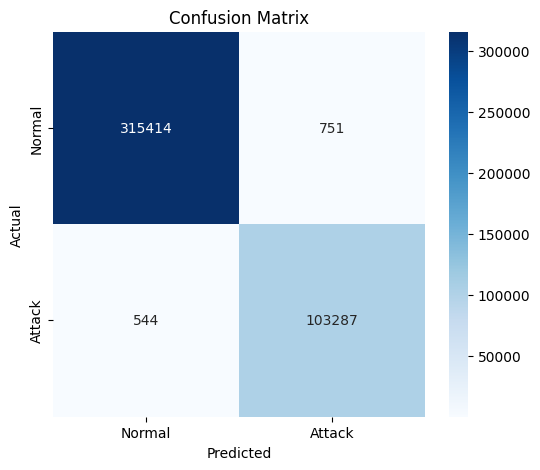

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()